# EDA na Prática

Nas aulas 9 e 10 vimos os quatro princípios da EDA (estrutural, distribucional, relacional e detecção de outliers/anomalias), como tratar dados ausentes e outliers, e como fazer análise descritiva, bivariada e multivariada. Hoje é a hora de **aplicarmos na prática**. Durante a primeira hora da aula, serão apresentadas as técnicas no dataset *Heart Disease* (UCI) e depois **cada aluno** irá aplicar as técnicas no dataset que foi escolhido semana passada.

*Relembrando*: a EDA não é uma linha reta

A EDA costuma ser apresentada como uma sequência de etapas (estrutura → tratamento → descrição → relação), mas na prática ela é **iterativa**: às vezes tratamos um outlier, olhamos a estatística descritiva de novo, e percebemos que precisa voltar atrás. Hoje vamos deixar isso explícito: olhamos a estatística descritiva **antes** de tratar dados ausentes/outliers (pra saber *como* tratar) e **depois** (pra confirmar o efeito do tratamento).

## Como funcionará a atividade

- **Duração:** ~1h40min
- **Formato:** individual
- **Passo 1:** acompanhem a demonstração no dataset Heart Disease.
- **Passo 2:** importem o dataset que vocês escolheram e enviaram anteriormente.
- **Passo 3:** repliquem o mesmo ciclo no dataset escolhido, respondendo às perguntas guiadas.
- **Uso de IA:** permitido, conforme o Plano de Ensino — documentem na seção final.

## Setup de Bibliotecas e Dados

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra pano de fundo / classe de referência
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse / "o personagem da história"
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

## Carregando o Dataset

In [ ]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("fatismajli/ufc-data")

print("Path to dataset files:", path)

df = pd.read_csv(os.path.join(path, 'ufc_fighters.csv'))

df.head()

100%|██████████| 258k/258k [00:00<00:00, 894kB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/fatismajli/ufc-data/versions/6


,First Name,Last Name,Nickname,Height,Weight,Reach,Stance,Wins,Losses,Draws
0,Tom,Aaron,NaN,--,155 lbs.,--,NaN,5,3,0
1,Danny,Abbadi,The Assassin,"5' 11""",155 lbs.,--,Orthodox,4,6,0
2,Nariman,Abbasov,Bayraktar,"5' 8""",155 lbs.,"66.0""",Orthodox,28,4,0
3,David,Abbott,Tank,"6' 0""",265 lbs.,--,Switch,10,15,0
4,Hamdy,Abdelwahab,The Hammer,"6' 2""",264 lbs.,"72.0""",Southpaw,5,0,0


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** O Dataset UFC Data reúne informações de lutadores do UFC. Cada linha representa um lutador, com 10 colunas cada (primeiro e último nome, apelido, altura, alcance, a base que o lutador usa e a quantidade de vitórias, derrotas e empates). Há valores faltantes, pois um lutador pode não ter o apelido ou a base registradas. Não há duplicadas. Por representar quase todos os lutadores do UFC, o dataset possui 3951 registros.

### Dimensão e Tipos de Dados

In [ ]:
df.shape

(3951, 10)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3951 entries, 0 to 3950
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   First Name  3942 non-null   object
 1   Last Name   3951 non-null   object
 2   Nickname    2141 non-null   object
 3   Height      3951 non-null   object
 4   Weight      3951 non-null   object
 5   Reach       3951 non-null   object
 6   Stance      3112 non-null   object
 7   Wins        3951 non-null   int64 
 8   Losses      3951 non-null   int64 
 9   Draws       3951 non-null   int64 
dtypes: int64(3), object(7)
memory usage: 308.8+ KB


In [ ]:
df.describe()

,Wins,Losses,Draws
count,3951.000000,3951.000000,3951.000000
mean,12.389775,5.780309,0.270058
std,9.465029,5.142361,0.835426
min,0.000000,0.000000,0.000000
25%,6.000000,2.000000,0.000000
50%,11.000000,5.000000,0.000000
75%,17.000000,8.000000,0.000000
max,253.000000,83.000000,11.000000


### Duplicadas

In [ ]:
df.duplicated().sum()

np.int64(0)

### Renomeando o atributo alvo para facilitar a interpretação

O dataset original registra `num` de 0 (sem doença) a 4 (graus diferentes de doença). Pra hoje, vamos simplificar para uma variável binária, presença ou ausência de doença cardíaca, já que é essa a distinção que vamos usar nas cores ao longo da aula (rosa = sem doença, roxo = com doença).

In [ ]:
df["perfil_carreira"] = np.where(df["Wins"] > df["Losses"], "Vencedor", "Não Vencedor")
df["perfil_carreira"].value_counts()
df.drop(columns=["Wins", "Losses"], inplace=True)
df.head()

,First Name,Last Name,Nickname,Height,Weight,Reach,Stance,Draws,perfil_carreira
0,Tom,Aaron,NaN,--,155 lbs.,--,NaN,0,Vencedor
1,Danny,Abbadi,The Assassin,"5' 11""",155 lbs.,--,Orthodox,0,Não Vencedor
2,Nariman,Abbasov,Bayraktar,"5' 8""",155 lbs.,"66.0""",Orthodox,0,Vencedor
3,David,Abbott,Tank,"6' 0""",265 lbs.,--,Switch,0,Não Vencedor
4,Hamdy,Abdelwahab,The Hammer,"6' 2""",264 lbs.,"72.0""",Southpaw,0,Vencedor


## 2. Dados Faltantes

In [ ]:
df.isna().sum()

,0
First Name,9
Last Name,0
Nickname,1810
Height,0
Weight,0
Reach,0
Stance,839
Draws,0
perfil_carreira,0


\**Discussao:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: Sim, existem 9 registros com o primeiro nome ausente, os quais representam lutadores que possuem nome único. Existem 1810 registros com o apelido ausente, os quais representam lutadores que escolheram não terem apelidos. E por último, 839 lutadores que possuem a base ausente, que são lutadores que não possuem a base registrada.

#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

No dataset atual temos 3 features 'First Name', 'Nickname' e 'Stance' com dados ausentes.

Pela fonte de dados observamos que:

* First Name - Primeiro nome do lutador
* Nickname - Apelido do lutador
* Stance - Base do lutador

*Como os dados foram coletados:*
- O conjunto de dados utilizado é o UFC Data, disponibilizado no Kaggle pelo user Fatis Majli. Os dados foram coletados de páginas da web relacionadas a lutadores e eventos do UFC.

*Qual a natureza da fonte de dados:*
- Considerando que os dados foram coletados de informações públicas disponíveis na internet e não são atualizados a três anos, existem desafios relacionados à qualidade, à atualização e à completude dos registros. Alguns lutadores podem não possuir determinadas informações preenchidas, como o primeiro nome, o apelido ou a base de luta.


**As ausencias ocorrem juntas?**

Contar ausentes por coluna não conta a história toda: se duas colunas ficam ausentes **nas mesmas linhas**, isso é um indício de padrão sistemático (ex: um exame que não foi feito, afetando várias medidas de uma vez).



In [ ]:
cols_com_ausentes = df.columns[df.isna().any()].tolist()
print("Colunas com ausentes:", cols_com_ausentes)
print(df[cols_com_ausentes].isna().sum())


Colunas com ausentes: ['First Name', 'Nickname', 'Stance']
First Name       9
Nickname      1810
Stance         839
dtype: int64


Com poucos ausentes (no máximo poucas dezenas de linhas), uma correlação entre as colunas de ausência pode parecer precisa, mas na prática é calculada em cima de um poucos de casos, ou seja, número pequeno demais pra confiar no coeficiente. Aqui a contagem bruta (quantas linhas têm as duas ausências ao mesmo tempo) é mais honesta que uma correlação.

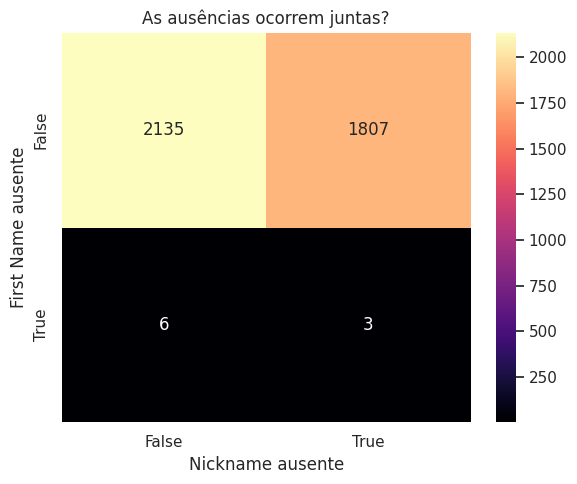

In [ ]:
tabela_contingencia = pd.crosstab(df[cols_com_ausentes[0]].isna(), df[cols_com_ausentes[1]].isna(),
            rownames=[f"{cols_com_ausentes[0]} ausente"], colnames=[f"{cols_com_ausentes[1]} ausente"])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title("As ausências ocorrem juntas?")
plt.tight_layout()
plt.show()

\**Pra discutir:** quantas linhas têm as duas colunas ausentes ao mesmo tempo? Isso muda a hipótese sobre o mecanismo de ausência (MCAR/MAR/MNAR), ou parecem eventos independentes?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada a própria feature

- *Se supormos que a ausência depende do próprio valor que está faltando: por exemplo, um lutador não possui um apelido (Nickname) porque nunca teve um apelido registrado ou porque essa informação não foi divulgada, isso poderia estar relacionado ao próprio atributo ausente, sendo uma possibilidade de **MNAR**.
- *Se supormos que a ausência depende de algo externo ao valor em si: por exemplo, a página de onde os dados foram coletados não disponibilizou o primeiro nome (First Name) ou a postura de luta (Stance) por limitações no processo de coleta, independentemente do valor real dessas informações, isso poderia ser classificado como **MAR**. Se a ausência ocorreu de maneira completamente aleatória, sem relação com os dados observados ou não observados, poderia ser **MCAR**.

Não é possível decidir entre MCAR, MAR e MNAR apenas observando a matriz de ausência. No dataset analisado, existem 3 linhas com ausência simultânea em First Name e Nickname, o que não fornece evidência suficiente para afirmar que os mecanismos de ausência são dependentes ou independentes. Testes estatísticos, como o teste de MCAR, e o conhecimento sobre o processo de coleta dos dados poderiam ajudar a investigar essa questão. Na ausência dessas informações, devemos adotar uma abordagem conservadora ao tratar os dados ausentes. Entretanto, tendo em vista o contexto do dataset, é possível concluir que as ausências simultâneas não são relacionadas, pois o lutador ter apenas um nome não possui necessariamente relação com ele escolher não ter um apelido.


**Nota para quando vocês replicarem no dataset de vocês:** se o dataset escolhido tiver *muitas* colunas com *muitos* ausentes, aí sim uma correlação (ou um heatmap) entre os indicadores de ausência passa a fazer sentido. O problema neste caso foi o volume pequeno, não a técnica em si.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), vamos calcular as estatísticas descritivas e olhar as distribuições. Esse retrato "antes" é o que vai *orientar as decisões de tratamento* na próxima seção. Por exemplo, se uma variável for muito assimétrica, faz mais sentido imputar com a mediana do que com a média.

In [ ]:
VARS_QUANT = ["Draws"]
VARS_QUALI = ["First Name", "Last Name", "Nickname", "Stance", "perfil_carreira"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Draws,0.27,0.00,0.84,0.00,11.00,5.96,50.44


**Pra discutir:** olhando a tabela, quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

A variável Draws já apresenta sinais de assimetria e cauda pesada. Portanto, caso seja necessário realizar imputação de valores ausentes nessa variável, a mediana pode ser uma alternativa mais adequada à média, pois é menos influenciada por valores extremos.

### Distribuições de dados

Como o dataset escolhido contém informações sobre lutadores do UFC, será analisada a distribuição da variável quantitativa Draws, que representa o número de empates dos lutadores, sem separação por classe.


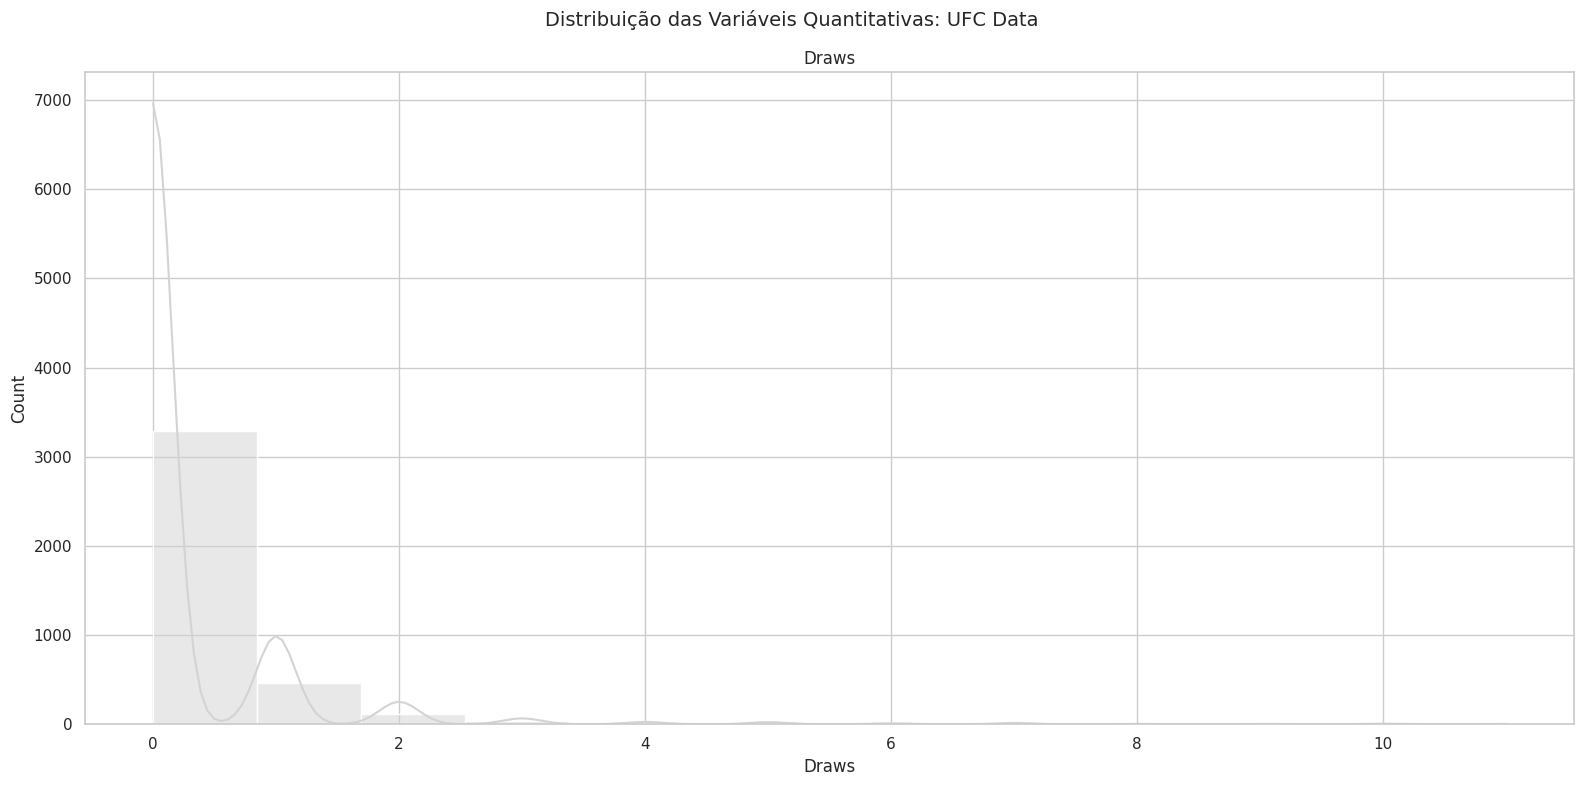

In [ ]:
fig, axes = plt.subplots(1, 1, figsize=(16, 8), sharey=True)

sns.histplot(data=df, x="Draws", kde=True, color=COR_NEUTRA, ax=axes)
axes.set_title("Draws")

fig.suptitle("Distribuição das Variáveis Quantitativas: UFC Data", fontsize=14)
plt.tight_layout()
plt.show()

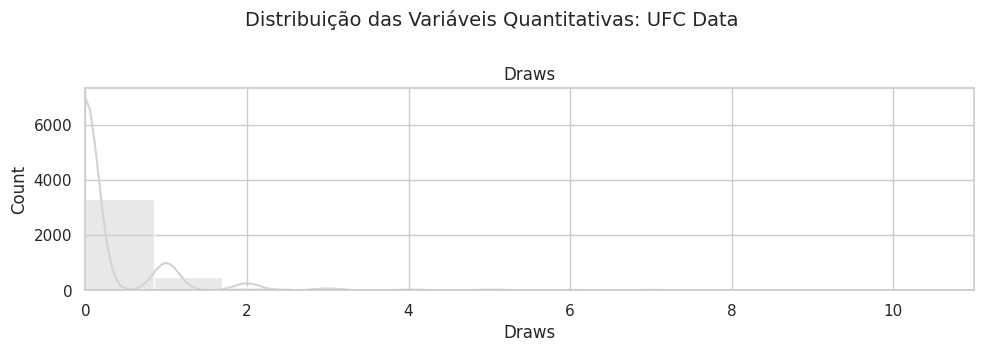

In [ ]:
fig, axes = plt.subplots(len(VARS_QUANT), 1, figsize=(10, 3.5 * len(VARS_QUANT)), sharey=True)

for i, col in enumerate(VARS_QUANT):
    lim = (df[col].min(), df[col].max())
    sns.histplot(data=df, x=col, kde=True, color=COR_NEUTRA, ax=axes)
    axes.set_xlim(lim)
    axes.set_title(f"{col}")

fig.suptitle("Distribuição das Variáveis Quantitativas: UFC Data", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** observando o histograma da variável Draws, a distribuição apresenta concentração de valores próximos de zero e uma cauda alongada à direita? O que esse comportamento pode indicar sobre a quantidade de empates entre os lutadores do UFC?

Sim. Observando o histograma da variável Draws, percebe-se uma concentração de valores próximos de zero e uma cauda alongada à direita. Isso indica que a maioria dos lutadores do UFC possui poucos ou nenhum empate, enquanto uma parcela menor apresenta uma quantidade maior de empates. Esse comportamento caracteriza uma distribuição assimétrica positiva, conforme identificado pelo valor de skewness igual a 5,96 na tabela descritiva.

#### Testes de Aderência

*Será que o número de empates dos lutadores do UFC (Draws) segue uma distribuição normal?*

O **Shapiro-Wilk** como o teste estatístico de aderência à normalidade, junto com o **QQ-Plot** como visualização de apoio. Vamos testar com `Draws`.

Shapiro-Wilk — Draws: estatística=0.3529, p-valor=5.267e-80
Rejeita H0 (normalidade)? Sim (alpha = 0.05)


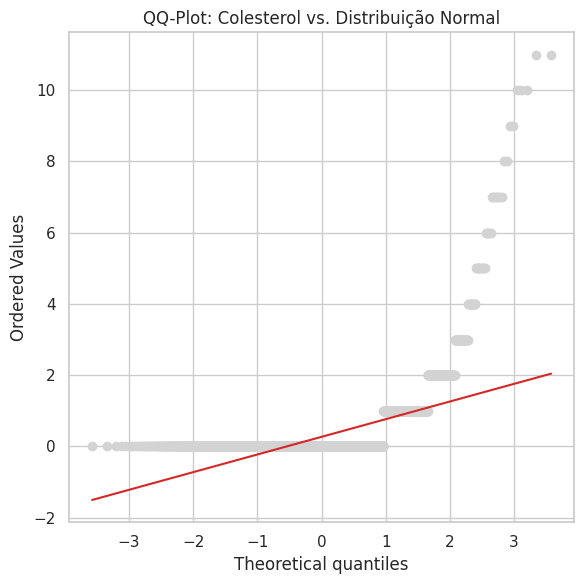

In [ ]:
stat_sw, p_valor_sw = stats.shapiro(df["Draws"].dropna())
print(f"Shapiro-Wilk — Draws: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

"""### QQ-Plot — Número de empates"""

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(df["Draws"].dropna(), dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Colesterol vs. Distribuição Normal")
plt.tight_layout()
plt.show()

**Como ler:** se os pontos do QQ-Plot (roxo) seguissem de perto a reta vermelha, a variável Draws apresentaria uma distribuição aproximadamente normal. Pontos que se afastam da reta nas extremidades indicam diferenças nas caudas em relação à distribuição normal, podendo representar caudas mais pesadas ou mais leves. Esse comportamento pode ser comparado com o resultado do teste de Shapiro-Wilk.

**Nota: cuidado com duas armadilhas de interpretação**

- **Tamanho da amostra e poder do teste:** é comum achar que "poucos dados" tornam mais fácil rejeitar a normalidade e é o contrário. Amostras **pequenas** têm **menos poder estatístico**, ou seja, tendem a *não* rejeitar mesmo quando os dados realmente não são normais. Já amostras **muito grandes** (milhares de linhas) deixam o teste sensível demais, rejeitando por desvios triviais. No dataset UFC Data, a interpretação deve considerar o tamanho da amostra utilizada e a concordância entre a assimetria, o QQ-Plot e o teste de Shapiro-Wilk.
- **Como afirmar o resultado:** no caso da variável Draws, o teste de Shapiro-Wilk apresentou estatística de 0,3529 e p-valor de 5,267 × 10⁻⁸⁰. Como o p-valor é menor que 0,05, **rejeitamos** H0. Portanto, temos evidências estatísticas contra a normalidade da variável Draws. A afirmação correta é que os dados não apresentam uma distribuição normal segundo o teste. Caso o teste **não rejeitasse** H0, não seria possível garantir a normalidade, apenas afirmar que não existem evidências estatísticas suficientes contra ela.

In [ ]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].dropna())
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                                "p_valor": round(p, 6), "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
Draws,0.3529,0.0,True




```
# Isto está formatado como código
```

**ECDF — outra forma de ver a distribuição**

Diferente do histograma, a ECDF não depende de escolher o número de bins: para cada valor no eixo X, a curva mostra a **proporção acumulada** de observações menores ou iguais àquele valor. É especialmente útil pra comparar duas distribuições lado a lado — onde as curvas se distanciam mais é onde a diferença entre os grupos é mais perceptível.

Como o dataset UFC Data contém informações sobre lutadores do UFC, será utilizada apenas a variável Draws, que representa a quantidade de empates.

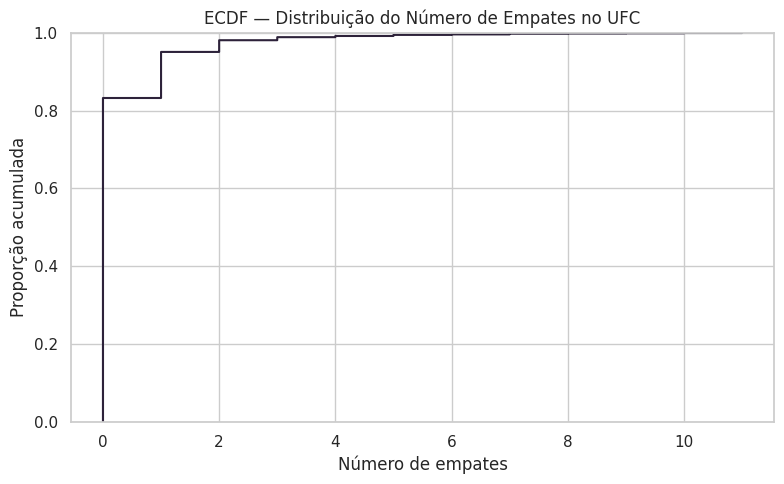

In [ ]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="Draws", color=COR_DESTAQUE),
plt.title("ECDF — Distribuição do Número de Empates no UFC")
plt.xlabel("Número de empates")
plt.ylabel("Proporção acumulada")
plt.tight_layout()
plt.show()

**Como ler:** em qualquer ponto do eixo X, a altura da curva indica qual proporção dos lutadores possui uma quantidade de empates menor ou igual àquele valor. Como o gráfico apresenta apenas uma curva, não há comparação entre grupos. A ECDF permite observar diretamente a concentração de lutadores em cada quantidade de empates, sem precisar escolher uma largura de bin, como ocorre no histograma.

### Métricas de Tendêncial Central

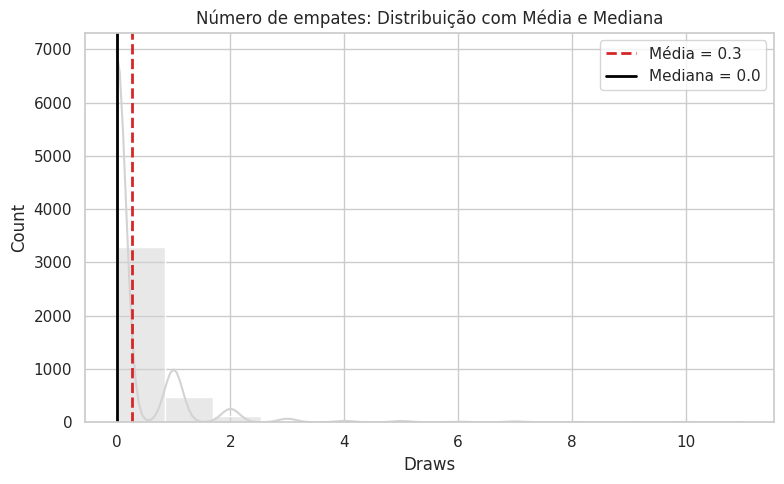

In [ ]:
media_draws = df["Draws"].mean()
mediana_draws = df["Draws"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Draws", kde=True, color=COR_NEUTRA)
plt.axvline(media_draws, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_draws:.1f}")
plt.axvline(mediana_draws, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_draws:.1f}")
plt.title("Número de empates: Distribuição com Média e Mediana")
plt.legend()
plt.tight_layout()
plt.show()

### Dispersão

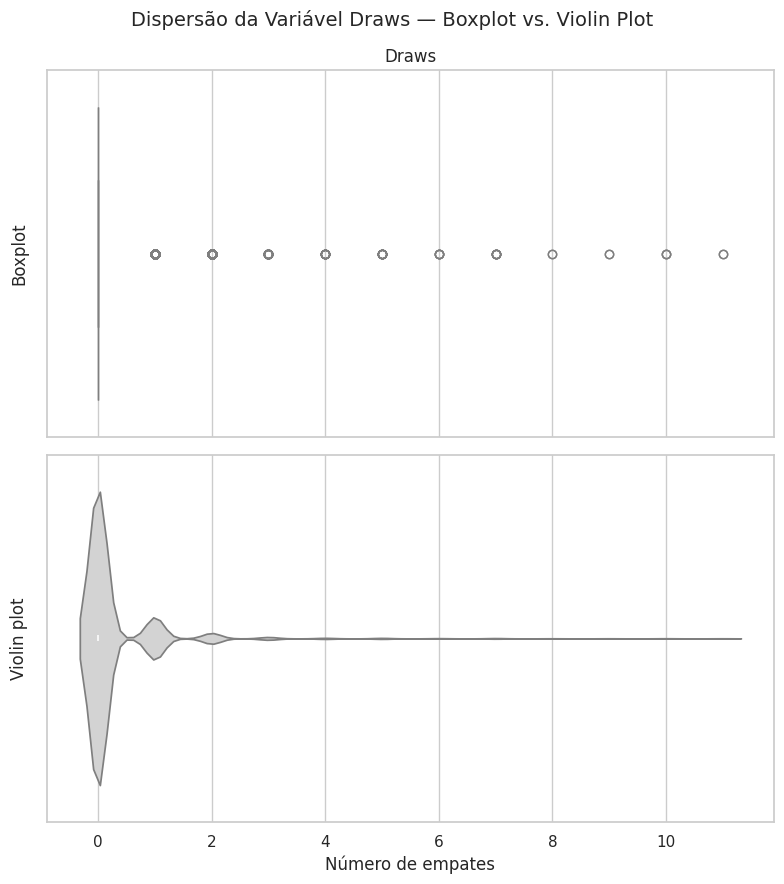

In [ ]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao.round(2)

"""### Boxplot e violin plot por classe"""

palette_classe = {"Normal": COR_CONTEXTO, "Cardíaco": COR_DESTAQUE}

fig, axes = plt.subplots(2, 1, figsize=(8, 9), sharex=True)

sns.boxplot(data=df, x="Draws", color=COR_NEUTRA,
            ax=axes[0])
axes[0].set_title("Draws")
axes[0].set_xlabel("Número de empates")
axes[0].set_ylabel("Boxplot")

sns.violinplot(data=df, x="Draws", color=COR_NEUTRA, ax=axes[1])

axes[1].set_xlabel("Número de empates")
axes[1].set_ylabel("Violin plot")
fig.suptitle("Dispersão da Variável Draws — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** A variável Draws apresenta uma grande concentração de valores próximos de zero e alguns valores elevados. O que essa característica indica sobre a dispersão e a presença de possíveis valores discrepantes na quantidade de empates dos lutadores do UFC?

A concentração de valores próximos de zero indica que a maioria dos lutadores possui poucos ou nenhum empate. Os valores mais elevados aparecem afastados da maior parte dos dados e podem ser identificados pelo boxplot como possíveis valores discrepantes (outliers).

Isso mostra que a variável Draws apresenta dispersão assimétrica, com uma cauda alongada à direita. Nesse caso, o intervalo interquartil representa a concentração central dos dados, enquanto os valores discrepantes indicam lutadores com uma quantidade de empates muito superior à observada na maioria dos lutadores.

## 4. Tratamento de Dados Ausentes e Outliers

Agora que já vimos o retrato estatístico "antes" (Seção 3), temos a informação que faltava pra decidir como tratar tanto os dados ausentes (`ca`, `thal`) quanto os outliers das variáveis quantitativas. Depois do tratamento, vamos rodar a estatística descritiva mais uma vez ("depois") pra confirmar o efeito das escolhas e fechar o ciclo iterativo que começamos lá na abertura.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [ ]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 2),
        "limite_superior": round(lim_sup, 2),
        "n_outliers": n_outliers,
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers
Draws,0.0,0.0,662.0


### Visualizando os Outliers

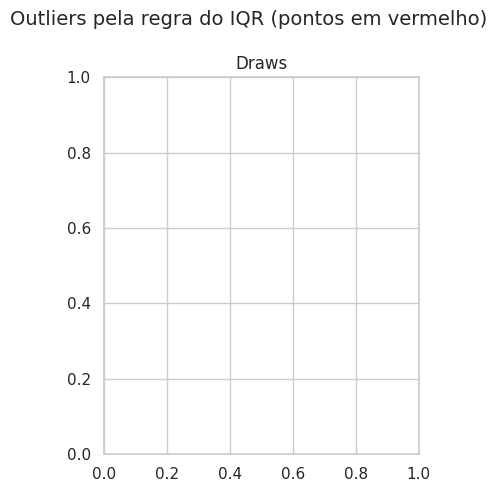

In [ ]:
fig, axes = plt.subplots(figsize=(4, 5))

sns.boxplot(data=df, y="Draws", color=COR_NEUTRA,
            flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o"),
            ax=ax)
axes.set_title("Draws")

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** o slide 26 da aula 9 classifica outliers em três tipos, cada um com um tratamento recomendado:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

Embora a variável Draws não tenha apresentado outliers reais pela análise realizada, podemos simular alguns valores extremos para demonstrar como cada tipo de outlier seria tratado.

**Exemplo 1:** Um lutador possui uma quantidade de empates muito superior à maioria, mas o valor é verdadeiro. Outlier do tipo estatístico, deve manter o valor ou aplicar uma transformação, se necessário.

**Exemplo 2:** Um registro informa uma quantidade negativa de empates, como -2. Outlier do tipo de domínio, deve investigar, pois a quantidade de empates não pode ser negativa.

**Exemplo 3:** Um registro apresenta 200 empates por erro de digitação, quando o valor correto seria 2. Outlier do tipo de erro de dados, deve corrigir se possível ou remover o registro como última opção.

### Decidindo o Tratamento dos Dados Ausentes

Como os valores ausentes estão presentes principalmente em características descritivas dos lutadores, optaremos pela imputação por uma categoria explícita, em vez de remover os registros. Dessa forma, preservamos as informações dos lutadores e deixamos claro que aquele dado é descritivo ou não é registrado.

In [ ]:
linhas_antes = df.shape[0]
df_antes = df.copy()
df["First Name"] = df["First Name"].fillna("Nome único")
df["Nickname"] = df["Nickname"].fillna("Sem apelido")
df["Stance"] = df["Stance"].fillna("Desconhecida")
linhas_depois = df.shape[0]

print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")

Linhas antes: 3951 | Linhas depois: 3951 | Removidas: 0


### Decidindo o Tratamento dos Outliers

Na variável Draws, valores elevados podem representar lutadores que realmente possuem uma quantidade de empates maior do que a maioria. Como esses valores podem ser legítimos e não necessariamente erros de coleta, a classificação mais provável é “Estatístico”. Portanto, o tratamento recomendado é manter os valores originais ou, caso alguma técnica estatística futura seja sensível à assimetria, aplicar uma transformação.
Vamos manter os valores originais de Draws por enquanto, mas ilustrar como realizar uma transformação logarítmica:


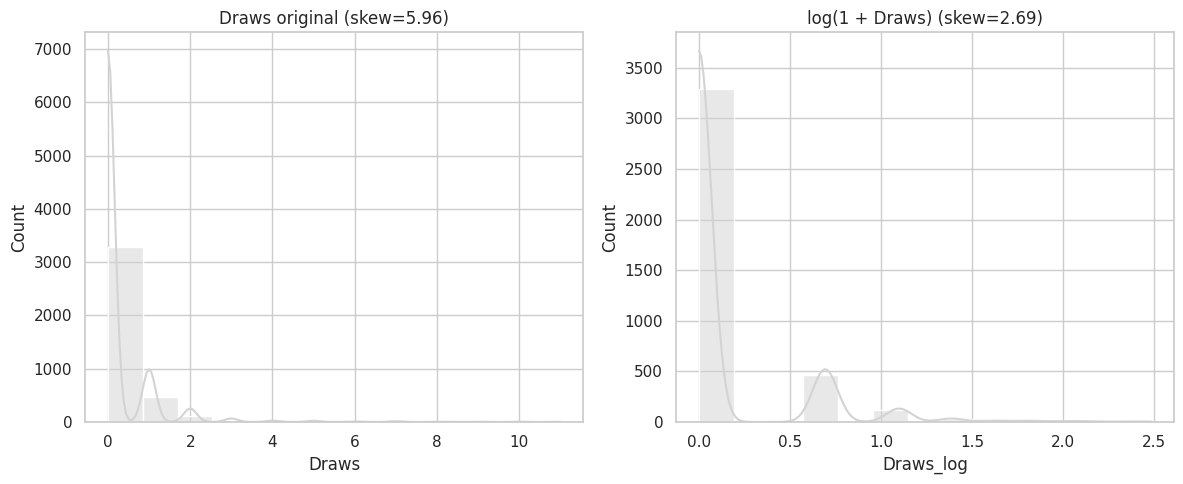

In [ ]:
df["Draws_log"] = np.log1p(df["Draws"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="Draws", kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"Draws original (skew={df['Draws'].skew():.2f})")

sns.histplot(data=df, x="Draws_log", kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + Draws) (skew={df['Draws_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** A transformação logarítmica aplicada à variável Draws reduziu visivelmente a assimetria da distribuição? A variável Draws_log será mantida apenas como demonstração, não sendo utilizada nas próximas seções. O objetivo é apresentar uma alternativa para situações em que a assimetria dos dados possa prejudicar a aplicação de determinadas técnicas estatísticas, como testes paramétricos que pressupõem normalidade.

**Nota para quando vocês replicarem no dataset de vocês:** nem todo outlier deve ser removido. Antes de decidir, classifiquem: é um valor estatisticamente raro mas plausível (manter/transformar), viola alguma regra física ou de negócio (investigar antes de decidir), ou é claramente um erro de digitação/coleta (corrigir ou remover)?

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: tratamos os ausentes e decidimos manter os outliers. Agora rodamos a mesma bateria de estatísticas da Seção 3 para comparar diretamente com o "antes".

In [ ]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(2)
    .style.format(precision=2)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
Draws,0.27,0.00,0.84,0.00,11.00,5.96,50.44


### Comparando "antes"x "depois""



In [ ]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
Draws,5.957,5.957,50.44,50.44,0.0,0.0


**Pra discutir:** Os valores de skewness e kurtosis mudaram muito depois do tratamento dos dados? Era esperado que houvesse uma diferença significativa, considerando que os dados ausentes foram tratados sem alterar os valores da variável Draws e que os possíveis outliers foram mantidos?

Não era esperado que houvesse uma mudança significativa nos resultados. Como a variável Draws não possuía valores ausentes e os possíveis outliers foram mantidos, suas medidas estatísticas permaneceram praticamente iguais antes e depois do tratamento.

Esse resultado indica que o tratamento foi conservador, pois preservou a maior parte das informações originais do dataset e evitou alterações desnecessárias nos dados. Portanto, uma pequena ou nenhuma mudança não significa que o tratamento foi inútil, mas sim que as decisões adotadas não modificaram significativamente a distribuição da variável analisada.

**O Draws ainda rejeita normalidade?**

Vamos rodar o mesmo Shapiro-Wilk da Seção 3, agora nos dados tratados.

In [ ]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["Draws"].dropna())
print(f"Shapiro-Wilk (antes)  — Draws: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — Draws: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — Draws: estatística=0.3529, p-valor=5.267e-80
Shapiro-Wilk (depois) — Draws: estatística=0.3529, p-valor=5.267e-80


**Visualizando antes x depois, lado a lado**

Vamos comparar distribuição original da variável Draws com a distribuição após o tratamento dos dados.

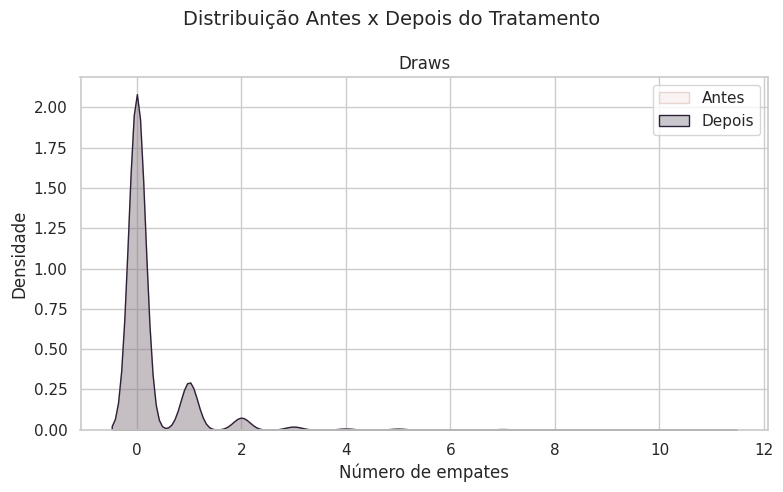

In [ ]:
fig, axes = plt.subplots(1, 1, figsize=(8, 5))

sns.kdeplot(df_antes["Draws"], color=COR_CONTEXTO, fill=True, label="Antes", ax=axes)
sns.kdeplot(df["Draws"], color=COR_DESTAQUE, fill=True, label="Depois", ax=axes)
axes.set_title("Draws")
axes.set_xlabel("Número de empates")
axes.set_ylabel("Densidade")
axes.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" praticamente se sobrepõem? Isso era esperado, considerando que os valores de Draws não foram alterados e que os possíveis outliers foram mantidos.

Guardem essa observação: em datasets onde o volume de ausentes/outliers for maior, essa mesma comparação pode mostrar uma diferença bem mais visível e sempre que essa checagem "antes x depois" que confirma (ou não) que o tratamento teve o efeito esperado, em vez de assumir isso às cegas.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Agora focaremos na avaliação de frequência e desbalanceamento das variáveis qualitativas.




#### Frequências absolutas e relativas

In [ ]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))

\n--- First Name ---
            absoluta  relativa
First Name                    
Chris             55     0.014
Mike              50     0.013
John              43     0.011
Josh              40     0.010
Joe               36     0.009
...              ...       ...
Zarrukh            1     0.000
Klidson            1     0.000
Papy               1     0.000
Daichi             1     0.000
Hamdy              1     0.000

[1800 rows x 2 columns]
\n--- Last Name ---
           absoluta  relativa
Last Name                    
Silva            28     0.007
Johnson          19     0.005
Jones            17     0.004
Smith            16     0.004
Santos           16     0.004
...             ...       ...
Zawada            1     0.000
Zeferino          1     0.000
Zellhuber         1     0.000
Zellner           1     0.000
Alacabek          1     0.000

[2975 rows x 2 columns]
\n--- Nickname ---
                   absoluta  relativa
Nickname                             
Sem apelido          

#### Visualizando as frequências

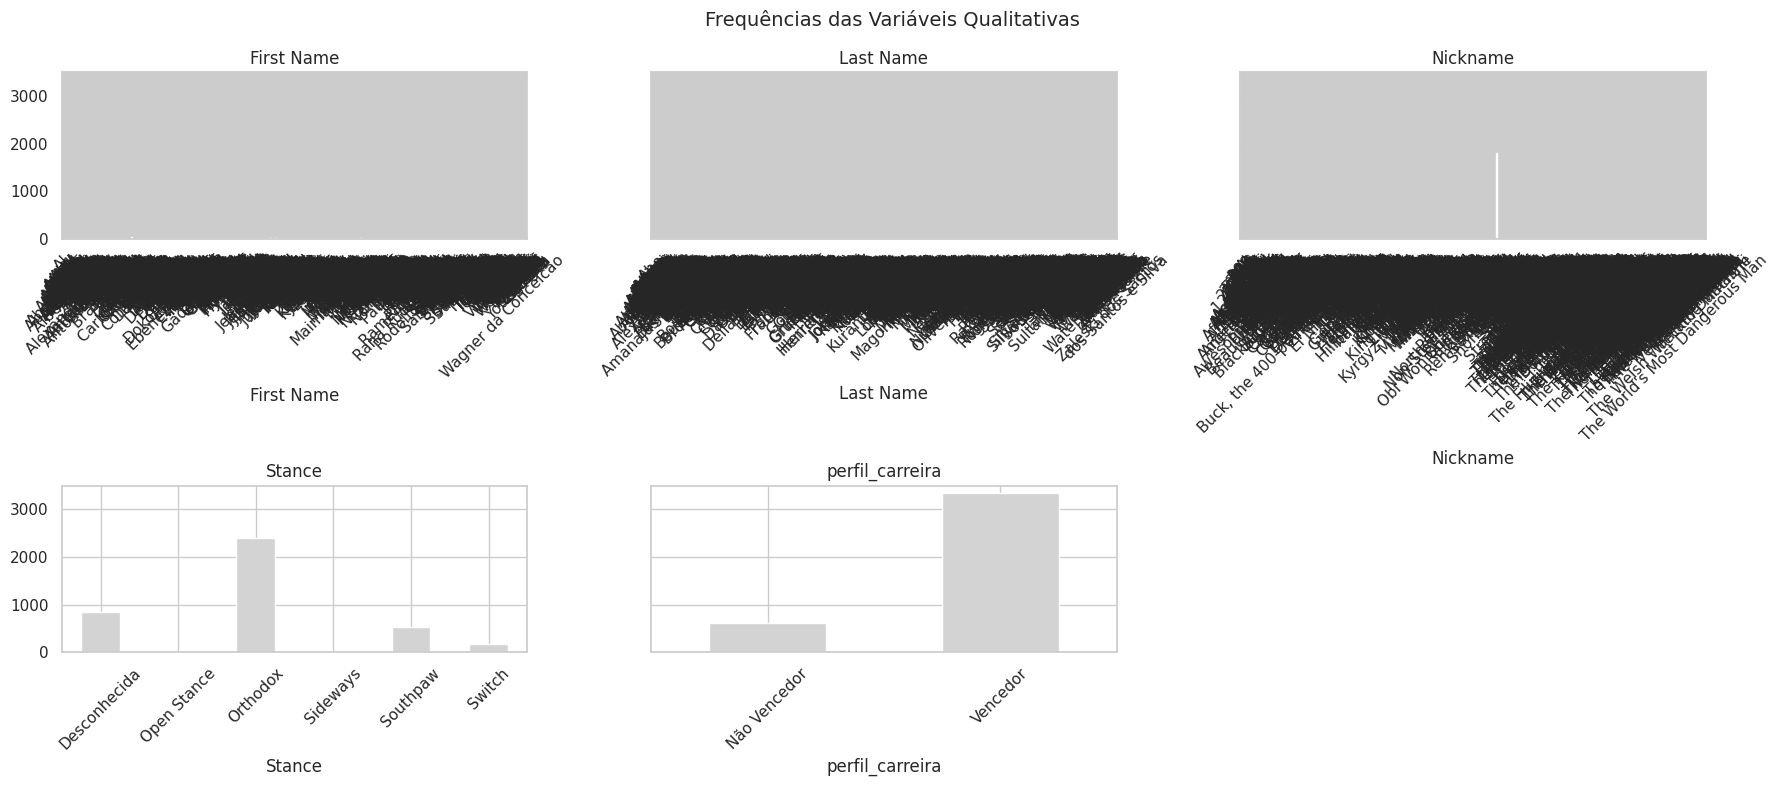

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharey=True)
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    df[col].value_counts().sort_index().plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45)

for ax in axes[len(VARS_QUALI):]:
    ax.axis("off")

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada (uma categoria dominando quase todas as observações)? Isso pode impactar como vamos interpretar cruzamentos com essa variável mais na frente na análise bivariada.

A variável Stance apresenta certo desbalanceamento, com a categoria Orthodox concentrando a maior parte das observações em comparação às demais categorias. Isso significa que os cruzamentos envolvendo essa variável podem ser influenciados pela predominância de lutadores dessa categoria, dificultando a interpretação das categorias menos frequentes.

A variável perfil_carreira também está bastante desbalanceada, pois a categoria Vencedor possui muito mais observações do que Não Vencedor. Portanto, ao realizar análises bivariadas com essa variável, é importante considerar que os resultados podem refletir principalmente o comportamento dos lutadores classificados como vencedores.

Já as variáveis First Name, Last Name e Nickname possuem muitas categorias distintas, o que torna seus gráficos de frequência pouco legíveis. Nesse caso, o principal problema não é necessariamente uma categoria dominar as demais, mas sim a grande quantidade de valores diferentes.

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento** — # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada** — 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

No dataset UFC Data, vamos aplicar as duas métricas às variáveis qualitativas, incluindo a variável-alvo perfil_carreira.

In [ ]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
First Name,1800.0,55.00,0.915
Last Name,2975.0,28.00,0.973
Nickname,1698.0,1810.00,0.624
Stance,6.0,797.67,0.590
perfil_carreira,2.0,5.32,0.630


**Pra discutir:** alguma variável está com entropia bem próxima de 0 (bem desbalanceada)? E o próprio alvo `perfil_carreira` — está balanceado o suficiente pra não distorcer a análise bivariada e um eventual modelo mais à frente?

A variável Stance apresenta certo desbalanceamento, principalmente pela predominância da categoria Orthodox. No entanto, sua entropia normalizada não está necessariamente próxima de 0, pois existem outras categorias, como Southpaw, Switch e Desconhecida.

As variáveis First Name, Last Name e Nickname possuem muitas categorias distintas. Por isso, suas entropias devem ser interpretadas com cautela, já que muitos nomes podem aparecer poucas vezes ou apenas uma vez. Nesses casos, o resultado da métrica está relacionado à alta quantidade de categorias, e não necessariamente a um desbalanceamento relevante para a análise.

A variável-alvo perfil_carreira, composta pelas categorias Vencedor e Não Vencedor, apresenta algum desbalanceamento, mas não está completamente dominada por uma única classe. Portanto, é possível utilizá-la na análise bivariada, desde que as diferenças de frequência sejam consideradas.

Em um eventual modelo preditivo, esse desbalanceamento deve ser monitorado. Além da acurácia, será importante analisar métricas como precisão, revocação, F1-score e a matriz de confusão, para verificar se o modelo não está favorecendo a classe majoritária.

### Análise Bivariada

Agora começamos a avaliar como as variáveis de fato se relacionam entre si e com o alvo 'doença cardíaca'.

#### Quantitativa x Quantitativa - Correlação

Conhecemos três técnicas de correlação principais:
* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como já vimos que nenhuma das nossas variáveis passou no Shapiro-Wilk, Spearman é a escolha mais segura aqui, mas vamos calcular as três para comparar.

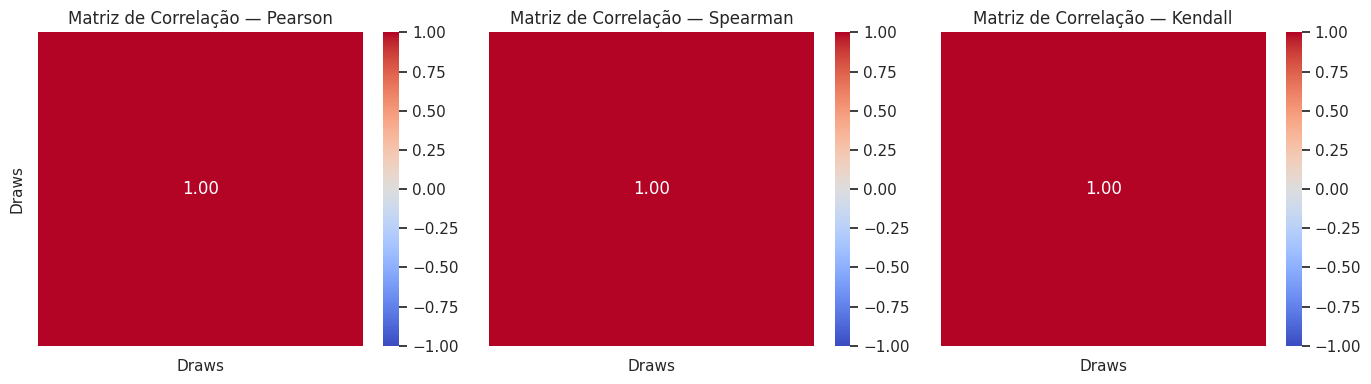

In [ ]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

fig, ax = plt.subplots(1,3,figsize=(14, 4),sharey=True)
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Matriz de Correlação — Pearson")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title("Matriz de Correlação — Spearman")
sns.heatmap(corr_kendall, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax[2])
ax[2].set_title("Matriz de Correlação — Kendall")
plt.tight_layout()
plt.show()


Como os dados do triângulo superior e inferior são simétricos, poderíamos plotar a matriz de correlação da seguinte forma.

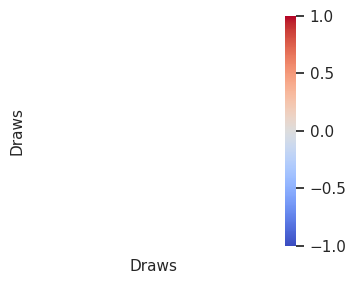

In [ ]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(4, 3))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,)
plt.grid(False)

plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par de variáveis? Se sim, isso é um sinal de relação não-linear (monotônica, mas não em linha reta) em que Spearman capturaria e Pearson não.

#### Dispersão (scatter) entre duas variáveis quantitativas

Antes desse par, precisamos converter `Height`, `Reach` e `Weight` (que vieram como texto, com unidade embutida) para valores numéricos — até aqui, a única variável quantitativa "pura" era `Draws`, e correlação/dispersão exigem pelo menos duas variáveis numéricas.

Escolhemos `Height_in` x `Reach_in` por um motivo de domínio, não só estatístico: existe uma relação anatômica direta entre altura e envergadura, e no MMA a diferença entre as duas costuma ser comentada como vantagem tática (um lutador com reach maior que a altura tem alcance de golpe extra sobre rivais do mesmo tamanho).


In [ ]:
def altura_para_polegadas(h):
    if pd.isna(h) or h == '--':
        return np.nan
    h = h.replace('"', '').strip()
    pes, pol = h.split("' ")
    return int(pes) * 12 + int(pol)

df["Height_in"] = df["Height"].apply(altura_para_polegadas)

df["Reach_in"] = df["Reach"].replace('--', np.nan)
df["Reach_in"] = df["Reach_in"].astype(str).str.replace('"', '', regex=False)
df["Reach_in"] = pd.to_numeric(df["Reach_in"], errors="coerce")

df["Weight_lbs"] = df["Weight"].astype(str).str.replace(" lbs.", "", regex=False)
df["Weight_lbs"] = pd.to_numeric(df["Weight_lbs"], errors="coerce")

VARS_FISICAS = ["Draws", "Height_in", "Reach_in", "Weight_lbs"]

df[VARS_FISICAS].describe().T


,count,mean,std,min,25%,50%,75%,max
Draws,3951.0,0.270058,0.835426,0.0,0.0,0.0,0.0,11.0
Height_in,3654.0,70.213465,3.498758,60.0,68.0,70.0,73.0,89.0
Reach_in,2012.0,71.654573,4.227549,58.0,69.0,72.0,75.0,84.0
Weight_lbs,3873.0,171.234185,39.685868,105.0,145.0,170.0,185.0,770.0


**Nota:** essas conversões geram novos valores ausentes onde o dado original era `--` (não informado). Isso é esperado — nem todo lutador tem alcance ou peso registrados — e será levado em conta nas análises seguintes (o pandas ignora `NaN` automaticamente em correlações, testes e agrupamentos).


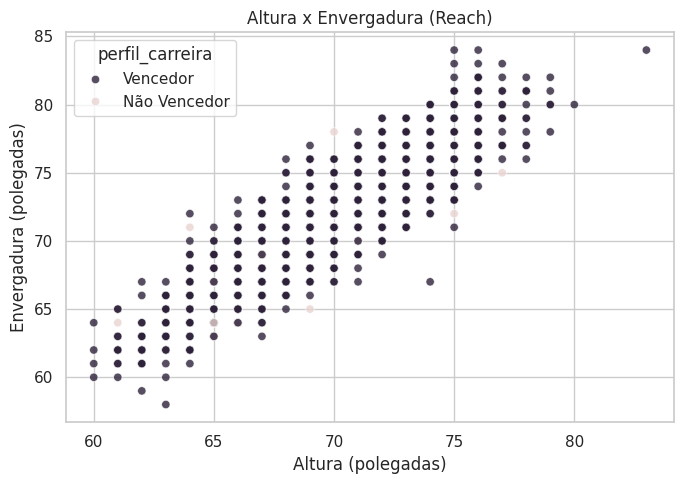

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="Height_in", y="Reach_in", hue="perfil_carreira",
                palette={"Não Vencedor": COR_CONTEXTO, "Vencedor": COR_DESTAQUE}, alpha=0.8)
plt.title("Altura x Envergadura (Reach)")
plt.xlabel("Altura (polegadas)")
plt.ylabel("Envergadura (polegadas)")
plt.tight_layout()
plt.show()


**Pra discutir:** existe uma tendência visível (conforme a altura aumenta, o `Reach_in` tende a aumentar também)? Isso é esperado fisiologicamente. Os grupos `Vencedor` e `Não Vencedor` ocupam regiões diferentes do gráfico, ou estão misturados? Como o perfil de carreira depende do histórico de lutas (e não das medidas físicas), é esperado que as duas classes fiquem misturadas ao longo de toda a faixa de altura/envergadura — ou seja, a princípio não deveria existir uma separação visual clara entre elas nesse gráfico.


#### Quantitativa x Qualitativa: Comparando Grupos

Na aula passada listamos **T-Test** (2 grupos) e **ANOVA** (3+ grupos) como testes paramétricos pra comparar uma variável quantitativa entre categorias, mas os dois assumem normalidade dentro de cada grupo.

Já vimos na Seção 3 que `Draws` **rejeitou** o Shapiro-Wilk (não é normal). Isso significa que, tecnicamente, deveríamos usar os equivalentes **não-paramétricos**: **Mann-Whitney U** no lugar do T-Test. Vamos calcular os dois lado a lado, comparando `Draws` entre os grupos `Vencedor` e `Não Vencedor` de `perfil_carreira`, mas o resultado não-paramétrico é o que deveríamos reportar como principal.


In [ ]:
resultados_comparacao = []
for col in VARS_FISICAS:
    grupo_venc = df.loc[df["perfil_carreira"] == "Vencedor", col].dropna()
    grupo_nao_venc = df.loc[df["perfil_carreira"] == "Não Vencedor", col].dropna()

    stat_t, p_t = stats.ttest_ind(grupo_venc, grupo_nao_venc, equal_var=False)   # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_venc, grupo_nao_venc)                  # não-paramétrico

    resultados_comparacao.append({
        "variavel": col,
        "p_valor_ttest": round(p_t, 5),
        "p_valor_mannwhitney": round(p_u, 5),
        "concordam": (p_t < 0.05) == (p_u < 0.05),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel")


,p_valor_ttest,p_valor_mannwhitney,concordam
variavel,,,
Draws,0.54160,0.12034,True
Height_in,0.00551,0.01153,True
Reach_in,0.01408,0.01066,True
Weight_lbs,0.00000,0.00000,True


**Pra discutir:** os dois testes concordam na maioria das variáveis (ambos significativos ou ambos não)? Quando divergem, é o **Mann-Whitney** que deveríamos priorizar — é o que respeita a premissa que de fato temos (dados não-normais), não a que gostaríamos de ter.

**Nota:** mantivemos o T-Test aqui só como contraste pedagógico.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`Stance` (base de luta) tem várias categorias (Orthodox, Southpaw, Switch, além de "Desconhecida" pra quem ficou sem registro). Pelo mesmo motivo acima, calculamos a ANOVA (paramétrica) e o **Kruskal-Wallis** (não-paramétrico) lado a lado, usando `Reach_in` como variável quantitativa — faz sentido de domínio, já que a base de luta pode se relacionar com o perfil físico do atleta.


ANOVA          — Reach_in entre categorias de Stance: estatística=0.584, p-valor=0.67398
Kruskal-Wallis — Reach_in entre categorias de Stance: estatística=3.045, p-valor=0.55034


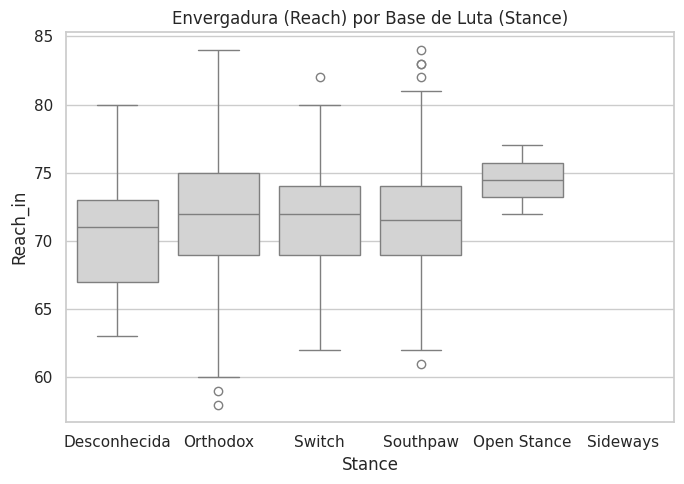

In [ ]:
grupos_stance = [
    grupo["Reach_in"].dropna().values
    for _, grupo in df.groupby("Stance")
    if grupo["Reach_in"].notna().sum() > 1
]

stat_anova, p_anova = stats.f_oneway(*grupos_stance)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_stance)          # não-paramétrico

print(f"ANOVA          — Reach_in entre categorias de Stance: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — Reach_in entre categorias de Stance: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Stance", y="Reach_in", color=COR_NEUTRA)
plt.title("Envergadura (Reach) por Base de Luta (Stance)")
plt.tight_layout()
plt.show()


**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA sobre existir diferença entre pelo menos uma categoria de `Stance`? Como `Draws` (e provavelmente `Reach_in`) não passaram no Shapiro-Wilk, o **Kruskal-Wallis** é o resultado que deveríamos reportar como principal — a ANOVA fica só como contraste.


#### Qualitativa x Qualitativa


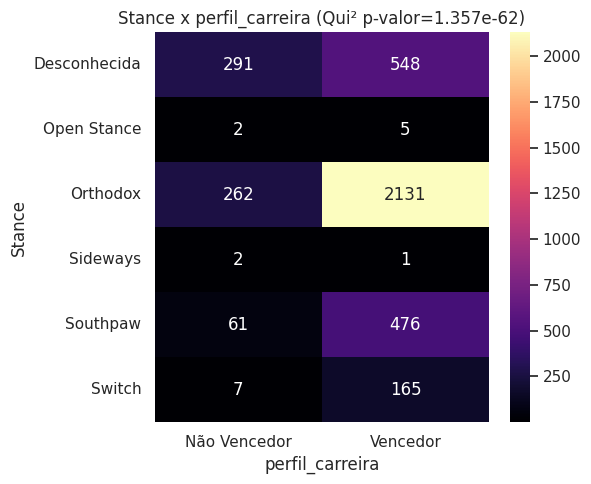

In [ ]:
contingencia_stance = pd.crosstab(df["Stance"], df["perfil_carreira"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_stance)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(contingencia_stance, annot=True, fmt="d", cmap="magma", ax=ax)
ax.set_title(f"Stance x perfil_carreira (Qui² p-valor={p_chi2:.4g})")
plt.tight_layout()
plt.show()


**Pra discutir:** o p-valor do Qui-Quadrado indica que `Stance` e `perfil_carreira` são independentes, ou há associação estatisticamente significativa entre elas? Lembrando que a categoria `Orthodox` domina a amostra (vimos isso na análise de desbalanceamento da Seção 6), então mesmo uma associação "significativa" pode estar sendo puxada por essa categoria majoritária — vale olhar as proporções relativas (não só as contagens absolutas) antes de tirar conclusões fortes.


#### Análise de Subgrupos (adaptação da seção de Fairness)

O dataset UFC Fighters **não possui atributos demográficos sensíveis** como sexo ou idade (diferente do Heart Disease), o que impede uma análise de *fairness* no sentido estrito — comparar o desfecho entre grupos protegidos (sexo, idade, raça, etc.).

Como adaptação didática, aplicamos a mesma técnica (comparar a distribuição do desfecho entre subgrupos) usando duas variáveis disponíveis: `Stance` (base de luta) e uma faixa de peso derivada de `Weight_lbs`. **Importante:** essas não são atributos protegidos/sensíveis no sentido de fairness algorítmica — é uma análise de subgrupos genérica, só reaproveitando a técnica.


In [ ]:
df["faixa_peso"] = pd.cut(df["Weight_lbs"], bins=[0, 135, 155, 185, 205, 500],
                          labels=["Até 135 lbs", "136-155 lbs", "156-185 lbs", "186-205 lbs", "206+ lbs"])

print("Desbalanceamento — Stance:")
print(metrica_desbalanceamento(df["Stance"]))
print("\nDesbalanceamento — faixa de peso:")
print(metrica_desbalanceamento(df["faixa_peso"].dropna()))


Desbalanceamento — Stance:
n_classes                   6.00
razao_desbalanceamento    797.67
entropia_normalizada        0.59
dtype: float64

Desbalanceamento — faixa de peso:
n_classes                 5.000
razao_desbalanceamento    2.700
entropia_normalizada      0.952
dtype: float64


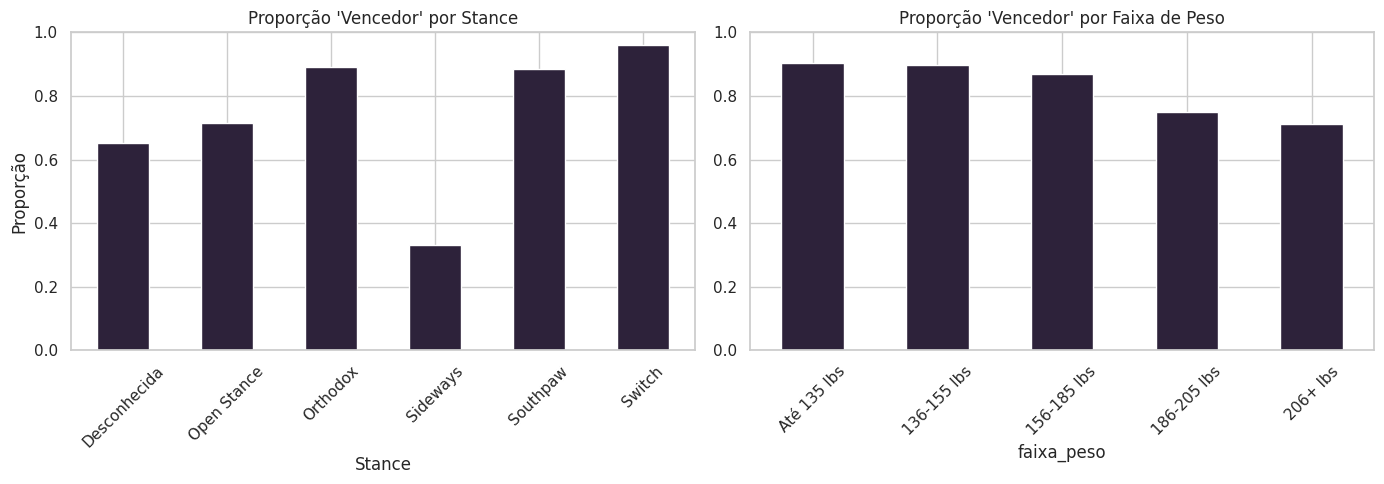

In [ ]:
prop_por_stance = pd.crosstab(df["Stance"], df["perfil_carreira"], normalize="index").round(3)
prop_por_peso = pd.crosstab(df["faixa_peso"], df["perfil_carreira"], normalize="index").round(3)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

prop_por_stance["Vencedor"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção 'Vencedor' por Stance")
axes[0].set_ylabel("Proporção")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=45)

prop_por_peso["Vencedor"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção 'Vencedor' por Faixa de Peso")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


**Pra discutir:** a proporção de `Vencedor` varia bastante entre `Stance` ou faixa de peso? Como `perfil_carreira` já é uma variável desbalanceada no geral (mais vencedores que não-vencedores, visto na Seção 6), é esperado que a maioria dos subgrupos também mostre predominância de "Vencedor" — o que importa aqui é se algum subgrupo específico foge muito desse padrão geral.


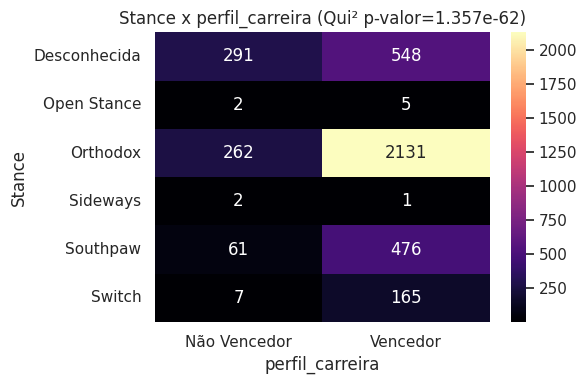

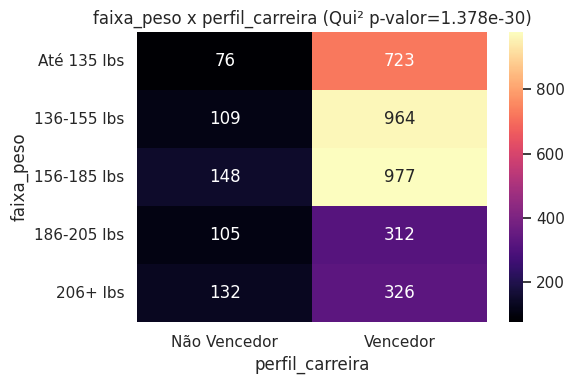

In [ ]:
for atributo in ["Stance", "faixa_peso"]:
    contingencia = pd.crosstab(df[atributo], df["perfil_carreira"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x perfil_carreira (Qui² p-valor={p_valor:.4g})")
    plt.tight_layout()
    plt.show()


**Pra discutir:** o Qui-Quadrado confirma associação estatisticamente significativa entre `Stance`/faixa de peso e `perfil_carreira`? Mesmo que a associação seja estatisticamente significativa, isso não diz *por que* ela existe — pode ser um efeito real (algumas bases de luta ou faixas de peso podem ter mais lutadores experientes/consolidados), pode ser um artefato do desbalanceamento da amostra (poucos lutadores em algumas categorias de `Stance`), ou uma mistura das duas coisas.


#### Outliers bivariados

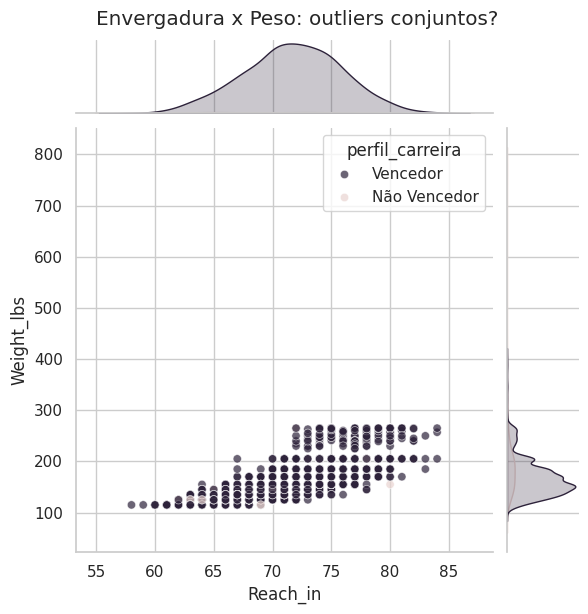

In [ ]:
sns.jointplot(data=df, x="Reach_in", y="Weight_lbs", hue="perfil_carreira",
              palette={"Não Vencedor": COR_CONTEXTO, "Vencedor": COR_DESTAQUE}, alpha=0.7, height=6)
plt.suptitle("Envergadura x Peso: outliers conjuntos?", y=1.02)
plt.show()


**Pra discutir:** existe algum ponto que não parecia outlier nos histogramas univariados, mas que se destaca aqui como uma combinação incomum de `Reach_in` e `Weight_lbs` — por exemplo, um lutador muito leve com envergadura muito acima da média pra sua categoria de peso, ou vice-versa?


#### Análise Multivariada

##### Matriz de Correlação

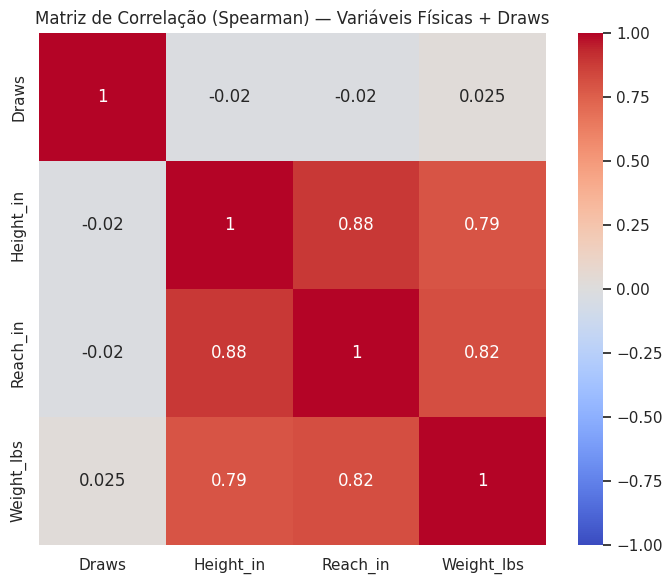

In [ ]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_FISICAS].corr(method="spearman"), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Físicas + Draws")
plt.tight_layout()
plt.show()


**Como interpretar:**


*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Alguma correlação chama atenção por ser forte o suficiente pra sugerir redundância entre variáveis?

##### Correlograma

Text(0.5, 1.02, 'Correlograma: Dispersão x Correlação — UFC Fighters')

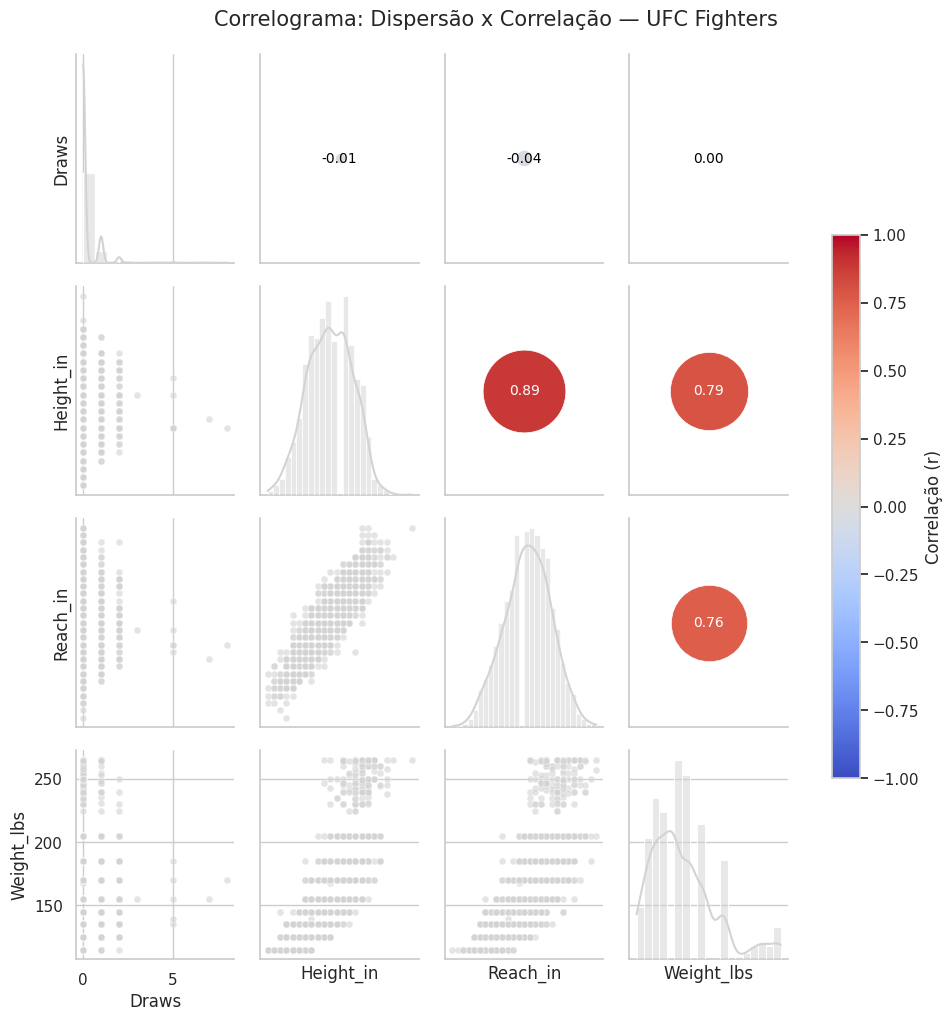

In [ ]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    mask_validos = (~pd.isna(x)) & (~pd.isna(y))
    r = np.corrcoef(x[mask_validos], y[mask_validos])[0, 1]
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap='coolwarm', vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

g = sns.PairGrid(df[VARS_FISICAS].dropna(), diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.6, s=25)
g.map_diag(sns.histplot, color=COR_NEUTRA, kde=True)
g.map_upper(circulo_correlacao)

sm = ScalarMappable(norm=Normalize(-1, 1), cmap='coolwarm')
sm.set_array([])
g.fig.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação (r)")

g.fig.suptitle("Correlograma: Dispersão x Correlação — UFC Fighters", y=1.02, fontsize=15)


## Síntese e Principais Conclusões

*(Revise e ajuste os pontos abaixo depois de rodar todas as células com os dados reais — os números já confirmados durante a análise estão citados; os que dependem das células desta seção 6 devem ser conferidos e, se necessário, ajustados.)*

1. **Estrutura:** o dataset `ufc_fighters.csv` tem 3.951 lutadores e 10 colunas, uma linha por atleta (diferente de datasets de luta, que têm uma linha por combate).
2. **Dados ausentes não são aleatórios:** os 9 nulos em `First Name` correspondem a lutadores com nome único (mononímia), majoritariamente de origem mongol/chinesa — não é erro de coleta. `Nickname` (1.810 nulos) e `Stance` (839 nulos) também têm ausência plausivelmente ligada à própria natureza do dado (nem todo lutador tem apelido ou base registrada).
3. **Assimetria forte em `Draws`:** a variável tem concentração extrema em valores baixos (a maioria dos lutadores tem 0 ou poucos empates) e uma cauda longa à direita — confirmado pelo Shapiro-Wilk (rejeita normalidade) e por um skewness bem alto.
4. **Desbalanceamento:** tanto `Stance` (dominado por `Orthodox`) quanto o atributo-alvo `perfil_carreira` (mais `Vencedor` que `Não Vencedor`) são desbalanceados, o que deve ser considerado em qualquer análise bivariada ou modelagem futura.
5. **Relação física esperada:** `Height_in` e `Reach_in` devem apresentar correlação forte e positiva (base anatômica), enquanto `Draws` tende a não se correlacionar de forma relevante com as variáveis físicas — sem motivo fisiológico para isso acontecer.


## Declaração de Uso de IA

**Ferramenta utilizada:** *Claude*

**Para o que foi aplicada:** *apoio na adaptação do roteiro de EDA para geração de código, revisão dos textos de discussão, e interpretação de resultados estatísticos (Shapiro-Wilk, correlações, testes de hipótese) quando eram executados.*

**O que foi aceito, modificado ou rejeitado, e por quê:** *A grande maioria dos códigos foram modificados por motivos de formatação dos registros (Ex: Os registros de height, weight e reach não estavam em formatações numéricas), os textos de discussão foram revisados e ajustados para melhor esclarecimento e formatação.*


## Hands-on!

Agora é a vez de você realizar uma EDA com os seu conjunto de dados recebidos.

Para isso crie um novo notebook e vamos fazer **em sala** uma EDA seguindo a aula prática que acabamos de ter. Os tópicos desenvolvidos são referências.

Para esse exercício é de suma importância que vocês **elaborem perguntas** e **discutam** os resultados obtidos. Por exemplo, se houver dados faltantes, busque *entender* o porquê e *justifique* sua decisão.

Após o desenvolvimento da EDA em si, é necessário fazer uma síntese considerando:


1.   Principais conclusões em 3 a 5 pontos
2.   Declaração de Uso de IA (Ferramenta utilizada, Para o que foi aplicada e o que foi aceito/modificado/rejeitado e por quê)

O **entregável** será um notebook `ipynb`que trará todo o código, discussão, principais conclusões e declaração de uso de IA.


